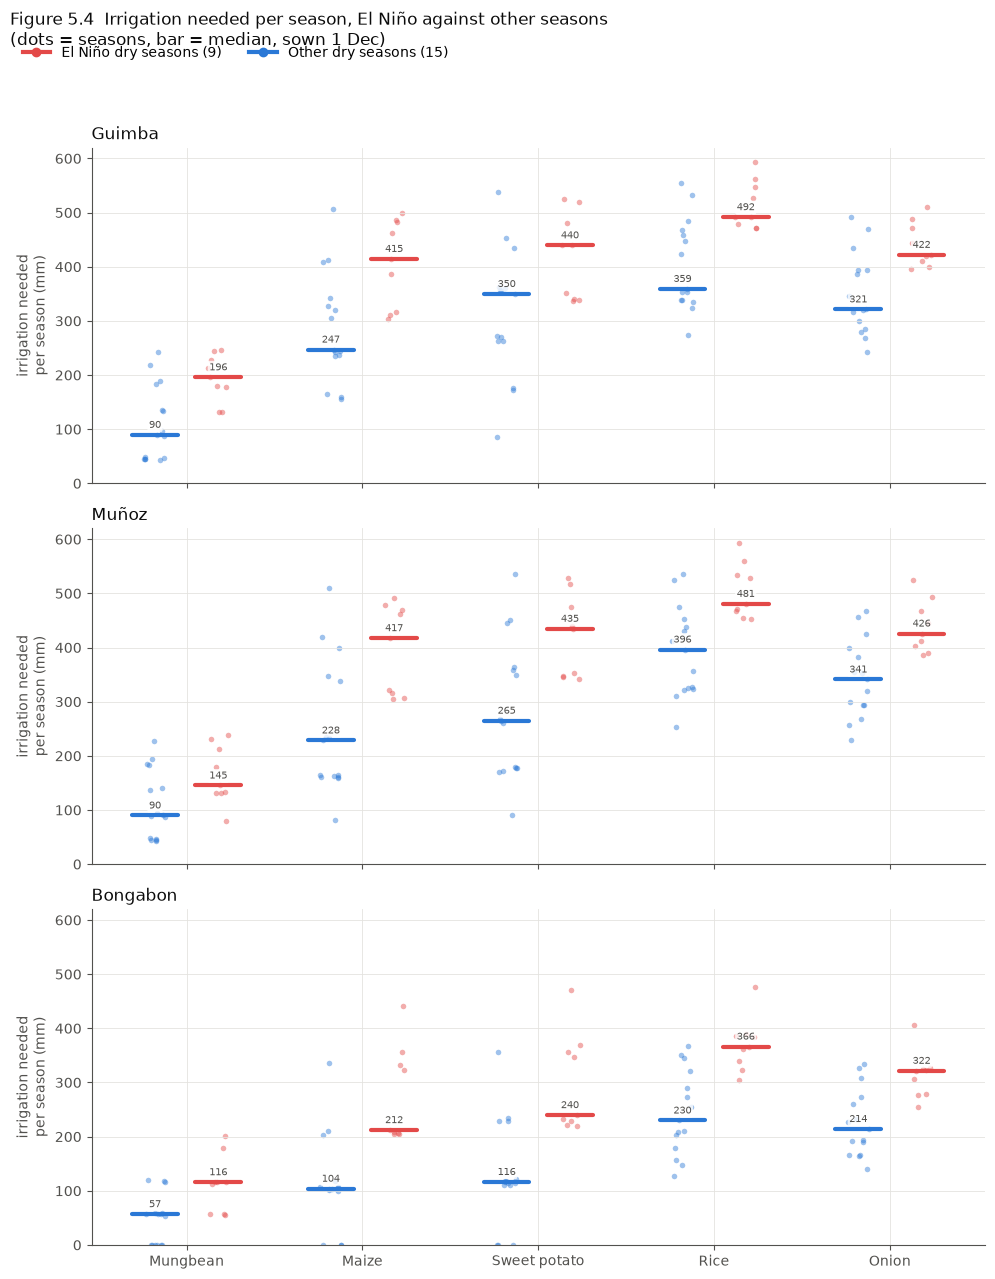

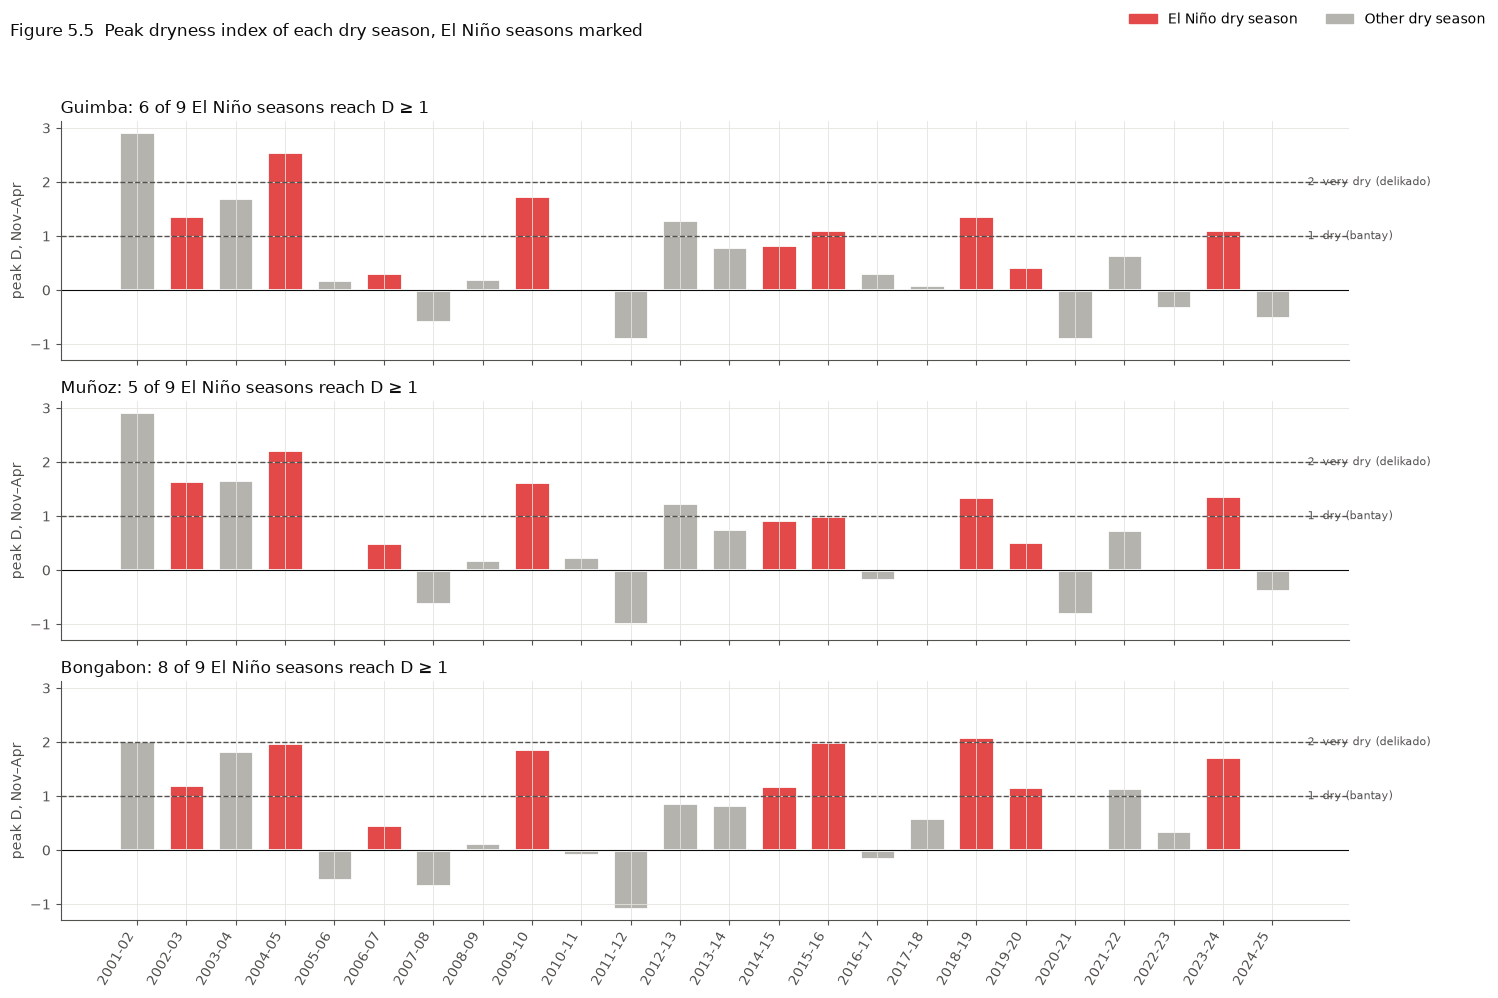

Guimba                     Muñoz                  Bongabon  \
                tag peak_d     month      tag peak_d     month      tag   
dry_season                                                                
2001-02     neutral   2.92  Apr 2002  neutral   2.92  Apr 2002  neutral   
2002-03     el_nino   1.37  Apr 2003  el_nino   1.65  Apr 2003  el_nino   
2003-04     neutral   1.70  Dec 2003  neutral   1.67  Dec 2003  neutral   
2004-05     el_nino   2.55  Nov 2004  el_nino   2.22  Nov 2004  el_nino   
2005-06     la_nina   0.18  Apr 2006  la_nina  -0.02  Apr 2006  la_nina   
2006-07     el_nino   0.32  Mar 2007  el_nino   0.51  Mar 2007  el_nino   
2007-08     la_nina  -0.58  Feb 2008  la_nina  -0.63  Feb 2008  la_nina   
2008-09     la_nina   0.20  Feb 2009  la_nina   0.19  Feb 2009  la_nina   
2009-10     el_nino   1.73  Feb 2010  el_nino   1.63  Jan 2010  el_nino   
2010-11     la_nina   0.02  Apr 2011  la_nina   0.25  Apr 2011  la_nina   
2011-12     la_nina  -0.91  Nov 2011  la_nina  -0.99  Nov 2011  la_nina   
2012-13     neutral   1.30  Jan 2013  neutral   1.25  Jan 2013  neutral   
2013-14     neutral   0.79  Feb 2014  neutral   0.75  Feb 2014  neutral   
2014-15     el_nino   0.83  Mar 2015  el_nino   0.92  Apr 2015  el_nino   
2015-16     el_nino   1.11  Apr 2016  el_nino   1.00  Apr 2016  el_nino   
2016-17     neutral   0.31  Apr 2017  neutral  -0.18  Apr 2017  neutral   
2017-18     la_nina   0.09  Mar 2018  la_nina  -0.02  Mar 2018  la_nina   
2018-19     el_nino   1.37  Dec 2018  el_nino   1.35  Dec 2018  el_nino   
2019-20     el_nino   0.43  Dec 2019  el_nino   0.52  Dec 2019  el_nino   
2020-21     la_nina  -0.92  Apr 2021  la_nina  -0.82  Apr 2021  la_nina   
2021-22     la_nina   0.65  Dec 2021  la_nina   0.74  Dec 2021  la_nina   
2022-23     la_nina  -0.33  Dec 2022  la_nina  -0.01  Apr 2023  la_nina   
2023-24     el_nino   1.11  Jan 2024  el_nino   1.36  Feb 2024  el_nino   
2024-25     neutral  -0.52  Jan 2025  neutral  -0.39  Jan 2025  neutral   

                             
           peak_d     month  
dry_season                   
2001-02      2.02  Nov 2001  
2002-03      1.20  Apr 2003  
2003-04      1.83  Dec 2003  
2004-05      1.98  Nov 2004  
2005-06     -0.56  Nov 2005  
2006-07      0.46  Feb 2007  
2007-08     -0.67  Dec 2007  
2008-09      0.14  Feb 2009  
2009-10      1.86  Feb 2010  
2010-11     -0.09  Apr 2011  
2011-12     -1.10  Nov 2011  
2012-13      0.88  Dec 2012  
2013-14      0.83  Feb 2014  
2014-15      1.19  Apr 2015  
2015-16      2.00  Nov 2015  
2016-17     -0.16  Nov 2016  
2017-18      0.60  Apr 2018  
2018-19      2.08  Nov 2018  
2019-20      1.16  Nov 2019  
2020-21      0.02  Apr 2021  
2021-22      1.16  Dec 2021  
2022-23      0.35  Apr 2023  
2023-24      1.73  Nov 2023  
2024-25      0.01  Dec 2024

In [2]:
# %%
# Ani: Monte Carlo results (pipeline/uncertainty.py)
#
# Reads pipeline/data/processed/risk_<town>.csv: one row per crop x water scenario.
#
# What the numbers mean
#   Water scenario     How many times the farmer can irrigate this dry season:
#                      rainfed = 0, limited_2 = about 2, limited_4 = about 4, full = as needed.
#                      Each irrigation refills the root zone once the crop starts to stress.
#   Failed X/9         In how many of the 9 El Nino dry seasons (2001-2025) the crop failed in the
#                      best-estimate run. Failed = 10+ days in a row of severe water stress while
#                      growing or flowering.
#   Wilson 95%         The likely range of the true failure rate given only 9 seasons.
#                      5/9 -> 27-81%: with so few seasons we cannot be precise.
#   Monte Carlo        200 runs, each with different but plausible inputs (root depth, Kc, season
#                      length, sowing day 16 Nov-16 Dec, yield, price, cost, failure threshold).
#                      p10 / p50 / p90 = the 10th, 50th (middle) and 90th percentile of the runs.
#   Net income         Yield x farmgate price in seasons that did not fail, minus the PSA production
#                      cost (paid even when the crop fails), PHP per hectare per season, averaged
#                      over the El Nino seasons.

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

DATA = Path("../pipeline/data/processed")      # notebook runs from notebooks/
TOWNS = {"guimba": "Guimba", "munoz": "Muñoz", "bongabon": "Bongabon"}
CROPS = ["mungbean", "maize", "sweet_potato", "rice", "onion"]
LABEL = {"rice": "Rice", "onion": "Onion", "mungbean": "Mungbean", "maize": "Maize",
         "sweet_potato": "Sweet potato"}
WATER = ["rainfed", "limited_2", "limited_4", "full"]
WLAB = {"rainfed": "0 (rain only)", "limited_2": "about 2", "limited_4": "about 4", "full": "as needed"}
WCOL = {"rainfed": "#e34948", "limited_2": "#eda100", "limited_4": "#1baf7a", "full": "#2a78d6"}
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": INK2,
                     "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "font.size": 10})

risk = pd.concat([pd.read_csv(DATA / f"risk_{t}.csv") for t in TOWNS], ignore_index=True)
peso = lambda v: ("−" if v < 0 else "") + f"₱{abs(v) / 1000:,.0f}k"
print(len(risk), "rows:", risk.muni.nunique(), "towns x", risk.crop.nunique(), "crops x", risk.water.nunique(), "water scenarios")


# %%
# Figure 1: What survives an El Nino dry season?
#
# How to read it
#   One grid per town. Rows = crops, columns = how many times the farmer can irrigate.
#   Each cell shows "failed X of 9 El Nino seasons" and, below it, the Wilson 95% range.
#   Colour = the Monte Carlo middle (p50) failure rate: green = safe, red = fails most years.
#   A cell is outlined when the Monte Carlo range (p10-p90) is wide (>= 50 points): that answer
#   flips with the inputs, so the app gives it LOW confidence.
#
# What to look for
#   Read across a row: how many irrigations a crop needs before it turns green.
#   Mungbean turns green earliest; rice and onion stay red until "as needed".

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("risk", ["#1baf7a", "#f0efec", "#e34948"])
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
for ax, (t, name) in zip(axes, TOWNS.items()):
    g = risk[risk.muni == t].set_index(["crop", "water"])
    val = np.array([[g.loc[(c, w), "mc_fail_en_p50"] for w in WATER] for c in CROPS])
    ax.imshow(val, cmap=cmap, vmin=0, vmax=1, aspect="auto")
    for i, c in enumerate(CROPS):
        for j, w in enumerate(WATER):
            r = g.loc[(c, w)]
            ax.text(j, i - 0.12, f"{int(r.fail_en_x)}/{int(r.fail_en_n)} failed", ha="center", va="center",
                    fontsize=9.5, color=INK, fontweight="bold")
            ax.text(j, i + 0.22, f"{r.fail_en_lo:.0%}–{r.fail_en_hi:.0%}", ha="center", va="center",
                    fontsize=8, color=INK2)
            if r.mc_fail_en_p90 - r.mc_fail_en_p10 >= 0.5:
                ax.add_patch(plt.Rectangle((j - 0.48, i - 0.48), 0.96, 0.96, fill=False, ec=INK, lw=1.8))
    ax.set_xticks(range(len(WATER)), [WLAB[w] for w in WATER]); ax.set_xlabel("irrigations this dry season")
    ax.set_yticks(range(len(CROPS)), [LABEL[c] for c in CROPS]); ax.grid(False)
    ax.set_title(name, loc="left", color=INK)
fig.suptitle("1  El Niño dry seasons: failed X of 9 (Wilson 95% range below; colour = Monte Carlo median; "
             "outline = low confidence)", x=0.01, ha="left", color=INK)
plt.tight_layout(rect=(0, 0, 1, 0.93)); plt.show()


# %%
# Figure 2: How much could the farmer earn (or lose)?
#
# How to read it
#   One panel per town. For each crop, four markers = the four water scenarios (colour legend).
#   Dot = middle run (p50) net income per hectare in El Nino seasons.
#   Line = the range from p10 to p90 across the 200 Monte Carlo runs (8 in 10 runs fall inside).
#   Below the dashed zero line the farmer loses money: a failed season still costs the full
#   production cost (e.g. about P61k for rice, P186k for onion).
#
# What to look for
#   With 0-2 irrigations most crops sit below zero; mungbean is the exception.
#   Onion with full water is far above everything else, but its line is also the longest:
#   high reward, high uncertainty (prices swing a lot).
#   The y-axis is "symlog" so both small (mungbean) and very large (onion) values stay readable.

fig, axes = plt.subplots(3, 1, figsize=(15, 12), sharex=True)
for ax, (t, name) in zip(axes, TOWNS.items()):
    g = risk[risk.muni == t].set_index(["crop", "water"])
    for i, c in enumerate(CROPS):
        for k, w in enumerate(WATER):
            r = g.loc[(c, w)]
            x = i + (k - 1.5) * 0.18
            ax.plot([x, x], [r.mc_net_en_p10, r.mc_net_en_p90], color=WCOL[w], lw=2.5, alpha=0.7)
            ax.plot(x, r.mc_net_en_p50, "o", color=WCOL[w], ms=7, mec="white", mew=1)
            if w in ("limited_2", "full"):
                ax.annotate(peso(r.mc_net_en_p50), (x, r.mc_net_en_p50), xytext=(6, 0),
                            textcoords="offset points", fontsize=7.5, color=INK2, va="center")
    ax.axhline(0, color=INK, ls="--", lw=1)
    ax.set_yscale("symlog", linthresh=50_000)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: peso(v)))
    ax.set_ylabel("net income per ha\n(El Niño seasons)"); ax.set_title(name, loc="left", color=INK)
axes[-1].set_xticks(range(len(CROPS)), [LABEL[c] for c in CROPS])
handles = [Line2D([], [], color=WCOL[w], marker="o", lw=2.5, label=f"{WLAB[w]} irrigations") for w in WATER]
fig.legend(handles=handles, loc="upper right", ncol=4, frameon=False)
fig.suptitle("2  Net income per hectare in El Niño seasons: dot = middle run (p50), line = p10–p90 of 200 runs",
             x=0.01, ha="left", color=INK)
plt.tight_layout(rect=(0, 0, 1, 0.95)); plt.show()


# %%
# Figure 3: Risk vs reward for one town and one water level
#
# How to read it
#   Each crop is one point. Left-right = chance of failing in an El Nino season (Monte Carlo p50;
#   the horizontal line spans p10-p90). Up-down = net income (p50; vertical line = p10-p90).
#   Top-left corner = best (earns well, rarely fails). Bottom-right = worst.
#   Change TOWN and W to see another farmer's situation.
#
# What to look for
#   This is the trade-off the planner resolves using the farmer's own priorities:
#   a "low risk" farmer is pulled left, an "income" farmer is pulled up.

TOWN, W = "guimba", "limited_2"         # try "bongabon" and "full"
g = risk[(risk.muni == TOWN) & (risk.water == W)].set_index("crop")
fig, ax = plt.subplots(figsize=(9, 6))
for c in CROPS:
    r = g.loc[c]
    ax.plot([r.mc_fail_en_p10, r.mc_fail_en_p90], [r.mc_net_en_p50] * 2, color=INK2, lw=1)
    ax.plot([r.mc_fail_en_p50] * 2, [r.mc_net_en_p10, r.mc_net_en_p90], color=INK2, lw=1)
    ax.plot(r.mc_fail_en_p50, r.mc_net_en_p50, "o", ms=11, color=WCOL[W], mec="white", mew=1.5)
    ax.annotate(f"{LABEL[c]}\n{peso(r.mc_net_en_p50)}, fails {int(r.fail_en_x)}/{int(r.fail_en_n)}",
                (r.mc_fail_en_p50, r.mc_net_en_p50), xytext=(10, 6), textcoords="offset points",
                fontsize=9, color=INK)
ax.axhline(0, color=INK, ls="--", lw=1)
ax.set_xlim(-0.05, 1.1); ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_yscale("symlog", linthresh=50_000); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: peso(v)))
ax.set_xlabel("chance of failing in an El Niño season (Monte Carlo p50, line = p10–p90)")
ax.set_ylabel("net income per ha, El Niño seasons")
ax.set_title(f"3  {TOWNS[TOWN]}, {WLAB[W]} irrigations: risk vs reward (top-left is best)", loc="left", color=INK)
plt.tight_layout(); plt.show()


# %%
# Table: the numbers behind the figures (El Nino seasons)
cols = {"fail_en_x": "failed", "fail_en_n": "of", "fail_en_lo": "wilson_lo", "fail_en_hi": "wilson_hi",
        "mc_fail_en_p50": "mc_fail_p50", "mc_irr_en_p50": "irrigation_mm", "mc_net_en_p10": "net_p10",
        "mc_net_en_p50": "net_p50", "mc_net_en_p90": "net_p90"}
tab = risk.set_index(["muni", "crop", "water"])[list(cols)].rename(columns=cols)
tab.round({"wilson_lo": 2, "wilson_hi": 2, "mc_fail_p50": 2, "irrigation_mm": 0,
           "net_p10": -2, "net_p50": -2, "net_p90": -2})